In [1]:
%matplotlib widget
from doocs4py_live_readout import  *

import pandas as pd




In [2]:
channels = {
    'pattern':       'XFEL.DIAG/TIMER.CENTRAL/MASTER/BUNCH_PATTERN',
    'bam_181_b1':    'XFEL.SDIAG/BAM/181.B1/ARRIVAL_TIME.absolute.TD',
    'bam_47_i1':     'XFEL.SDIAG/BAM/47.I1/ARRIVAL_TIME.absolute.TD',
#    'bam_203_b1':    'XFEL.SDIAG/BAM/203.B1/ARRIVAL_TIME.absolute.TD',
#    'bam_392_b2':    'XFEL.SDIAG/BAM/392.B2/ARRIVAL_TIME.absolute.TD',
#    'bam_414_b2':    'XFEL.SDIAG/BAM/414.B2/ARRIVAL_TIME.absolute.TD',
#    'bam_1932m_tl':  'XFEL.SDIAG/BAM/1932M.TL/ARRIVAL_TIME.absolute.TD',
#    'bam_1932s_tl':  'XFEL.SDIAG/BAM/1932S.TL/ARRIVAL_TIME.absolute.TD',
#    'bam_2461_s1':   'XFEL.SDIAG/BAM/2461.S1/ARRIVAL_TIME.absolute.TD',
#    'bam_2955_s3':   'XFEL.SDIAG/BAM/2955.S3/ARRIVAL_TIME.absolute.TD',
#    'bam_2473_s2':   'XFEL.SDIAG/BAM/2473.S2/ARRIVAL_TIME.absolute.TD',
#    'gun_sp_ampl':   'XFEL.RF/LLRF.SUMVOLTAGE_CTRL/GUN.I1/SP_AMPL.TD',
    'gun_ampl':      'XFEL.RF/LLRF.CONTROLLER/VS.GUN.I1/AMPL',
#    'gun_sp_phase':  'XFEL.RF/LLRF.SUMVOLTAGE_CTRL/GUN.I1/SP_PHASE.TD',
    'gun_phase':     'XFEL.RF/LLRF.CONTROLLER/VS.GUN.I1/PHASE',
    'toroid_charge': 'XFEL.DIAG/TOROID/TORA.25.I1/CHARGE.TD',
#    'bunch_pattern2':'XFEL.DIAG/TIMINGINFO/TIME1.BUNCH_PATTERN/CHANNEL.TD',
}

In [2]:
channels = {
    'pattern':       'FLASH.DIAG/TIMER/FLASHCPUTIME1.0/BUNCH_PATTERN',
    'UBC1':          'FLASH.SDIAG/BAM/FL0.UBC1/ARRIVAL_TIME.absolute.TD',
    'DBC1':          'FLASH.SDIAG/BAM/FL0.UBC1/ARRIVAL_TIME.absolute.TD',
    'DBC2':          'FLASH.SDIAG/BAM/FL0.DBC2/ARRIVAL_TIME.absolute.TD',
    'LOLA':          'FLASH.SDIAG/BAM/FL1.LOLA/ARRIVAL_TIME.absolute.TD',
    'SEED':          'FLASH.SDIAG/BAM/FL2.SEED5/ARRIVAL_TIME.absolute.TD',
    'gun_sp_ampl':   'FLASH.RF/LLRF.SUMVOLTAGE_CTRL/GUN/SP_AMPL.TD',
    'gun_ampl':      'FLASH.RF/LLRF.CONTROLLER/VS.GUN/AMPL.SAMPLE',
    'gun_sp_phase':  'FLASH.RF/LLRF.SUMVOLTAGE_CTRL/GUN/SP_PHASE.TD',
    'gun_phase':     'FLASH.RF/LLRF.CONTROLLER/VS.GUN/PHASE.SAMPLE',
    'gun_ampl_td':   'FLASH.RF/LLRF.CONTROLLER/VS.GUN/AMPL.TD',
    'gun_phase_td':  'FLASH.RF/LLRF.CONTROLLER/VS.GUN/PHASE.TD',

    'toroid_charge': 'FLASH.DIAG/TOROID/3GUN/CHARGE.TD',
}

In [29]:
t1=time.time()
data = {}
for name, addr in channels.items():
    try:
        #data[name] = pydoocs.read(addr)
        data[name] = doocs4py.get(addr)
    except Exception as e:
        print(f'Fehler bei {name} ({addr}): {e}')
print(time.time()-t1)

0.013419151306152344


In [89]:
t1=time.time()
data=read_channels_sync(channels, retries=150, retry_wait=0.001)
print(time.time()-t1)

0.05952811241149902


In [90]:
list(data.keys())

[2741240447]

In [91]:
data[list(data.keys())[0]].keys()

dict_keys(['UBC1', 'DBC1', 'DBC2', 'LOLA', 'SEED', 'gun_sp_ampl', 'gun_ampl', 'gun_sp_phase', 'gun_phase', 'gun_ampl_td', 'gun_phase_td', 'toroid_charge', 'pattern'])

In [92]:
data[list(data.keys())[0]]['gun_phase_td'].keys()

dict_keys(['t', 'y', 'timestamp'])

In [93]:
mask_data(data[list(data.keys())[0]],3, facility='FLASH',tol=0.01)

{'pattern': array([], shape=(0, 2), dtype=object),
 'UBC1': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'DBC1': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'DBC2': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'LOLA': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'SEED': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'gun_sp_ampl': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'gun_sp_phase': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'gun_ampl_td': {'t': array([], dtype=float64),
  'y': array([], dtype=float32),
  'bunch_idx': array([], dtype=int64)},
 'gun_phase_td'

In [94]:
data[list(data.keys())[0]]['toroid_charge']['t'][:10]

array([700.     , 700.99695, 701.9939 , 702.99084, 703.9878 , 704.98474,
       705.9817 , 706.97864, 707.9756 , 708.97253], dtype=float32)

In [95]:
decode_dest(data[list(data.keys())[0]]['pattern']['y'])[:20,0]

array([700.0, 700.11076923, 700.22153846, 700.33230769, 700.4430769200001,
       700.55384615, 700.66461538, 700.7753846100001, 700.8861538399999,
       700.99692307, 701.1076922999999, 701.21846153, 701.32923076,
       701.4399999899999, 701.55076922, 701.66153845, 701.77230768,
       701.88307691, 701.99384614, 702.10461537], dtype=object)

In [96]:
np.shape(data[list(data.keys())[0]]['toroid_charge']['y'])

(802,)

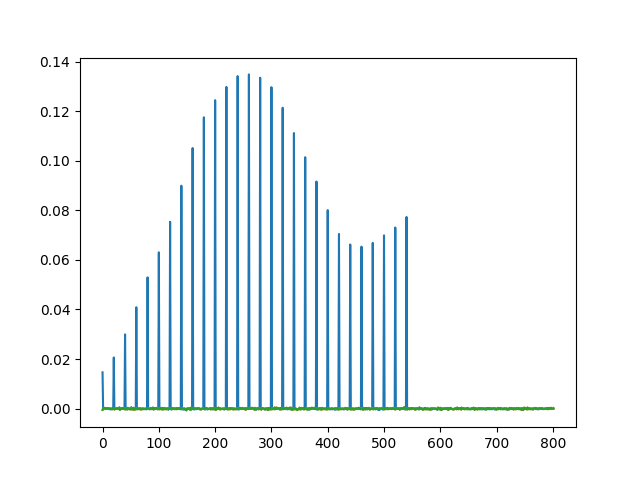

In [98]:
plt.plot(data[list(data.keys())[0]]['toroid_charge']['y'])
plt.show()

In [99]:
data_extr=decode_dest(data[list(data.keys())[0]]['pattern']['y'])

In [100]:
data_extr

array([[700.0, nan],
       [700.11076923, nan],
       [700.22153846, nan],
       ...,
       [1499.64307137, nan],
       [1499.7538406, nan],
       [1499.8646098299998, nan]], dtype=object)

In [134]:
save_scan_data('2026-09-08_21-30-00_gun_phase_scan_fast.hdf5',data)

#### GUN phase scan fast vs many bunches 

In [68]:
import importlib
import doocs4py_live_readout
importlib.reload(doocs4py_live_readout)

<module 'doocs4py_live_readout' from '/home/jzemella/PYTHON/BAM/doocs4py_live_readout.py'>

In [129]:
data=read_channels_sync(channels, retries=150, retry_wait=0.001)


In [130]:
data_masked=doocs4py_live_readout.mask_data(data[list(data.keys())[0]],
                                            condition="GnD (Gun dump/DUMP)",
                                            pattern_key='pattern',
                                            facility='FLASH',
                                            tol=0.1)

In [77]:
from scipy.optimize import curve_fit


def gaussAsymSuper_function(x,a,x0,sigma,e,n):
# define super gaussian function g(x) = a*Exp(-(x-x0)^n/(2 *abs(sigma*(1-sign(x-x0)))^n)
# inputs: amplitude a; x-shift x0; width sigma; skewness parameter e; offset a0; 
# output: g(x)
    return a*np.exp(-np.abs((x-x0))**np.abs(n)/(2.0*(np.abs(sigma*(1.0-np.sign(x-x0)*e)))**np.abs(n))) #+ mp

def gauss_function(x,a,x0,sigma):
# define super gaussian function g(x) = a*Exp(-(x-x0)^n/(2 *abs(sigma*(1-sign(x-x0)))^n)
# inputs: amplitude a; x-shift x0; width sigma; skewness parameter e; offset a0; 
# output: g(x)
    return  gaussAsymSuper_function(x,a,x0,sigma,0,2)



In [114]:
def thirdOrdExtremum(popt):
    p=2/3*popt[1]/popt[0]
    q=popt[2]/3/popt[0]
    return [-p/2 + np.sqrt((p/2)**2-q) ,-p/2 - np.sqrt((p/2)**2-q)] 

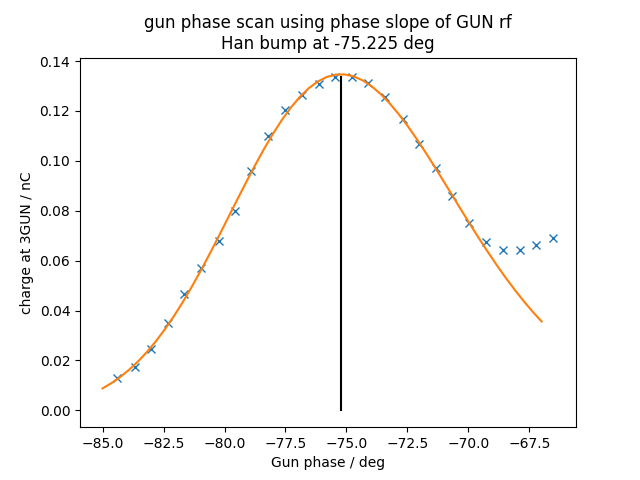

[-43.231205333304054, -75.2254955540694]


In [132]:
x,y=data_masked['gun_phase_td']['y'],data_masked['toroid_charge']['y']

popt=np.polyfit(x[x<-70],np.log(y[x<-70]),3)
yfit=np.polyval(popt,xfit)
yfit=np.exp(yfit)

extremum=thirdOrdExtremum(popt)

plt.figure()
plt.plot(x,y,'x')
plt.plot(xfit,yfit)
plt.xlabel('Gun phase / deg')
plt.ylabel('charge at 3GUN / nC')
plt.title(f'gun phase scan using phase slope of GUN rf\nHan bump at {extremum[1]:.3f} deg')

plt.plot([extremum[1],extremum[1]],[0,np.max(y)],'k')

plt.show()

print(thirdOrdExtremum(popt))

In [133]:
scan_data=doocs4py_live_readout.run_scan(np.linspace(-85,-65,26),'FLASH.RF/LLRF.CONTROLLER/CTRL.GUN/SP.PHASE' , channels, wait=0.5)

In [135]:
save_scan_data('2026-09-08_21-32-00_gun_phase_scan_multi-bunch.hdf5',data)

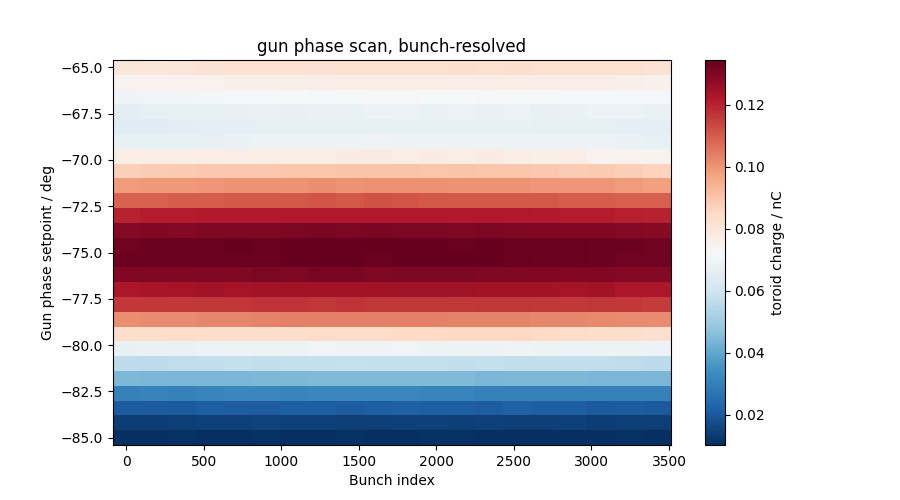

In [136]:


setpoints = []
rows = []  # eine Zeile pro Shot: Werte indiziert nach bunch_idx

for mp_id, entry in scan_data.items():
    dm = mask_data(entry, condition="GnD (Gun dump/DUMP)", facility='FLASH', tol=0.01)
    setpoints.append(entry['setpoint'])
    rows.append(dict(zip(dm['toroid_charge']['bunch_idx'], dm['toroid_charge']['y'])))

all_bunches = sorted(set().union(*[r.keys() for r in rows]))
bunch_to_col = {b: c for c, b in enumerate(all_bunches)}

M = np.full((len(rows), len(all_bunches)), np.nan)
for row_i, r in enumerate(rows):
    for b, y in r.items():
        M[row_i, bunch_to_col[b]] = y

plt.figure(figsize=(9, 5))
plt.pcolormesh(all_bunches, setpoints, M, shading='nearest', cmap='RdBu_r')
plt.colorbar(label='toroid charge / nC')
plt.xlabel('Bunch index')
plt.ylabel('Gun phase setpoint / deg')
plt.title('gun phase scan, bunch-resolved')
plt.show()

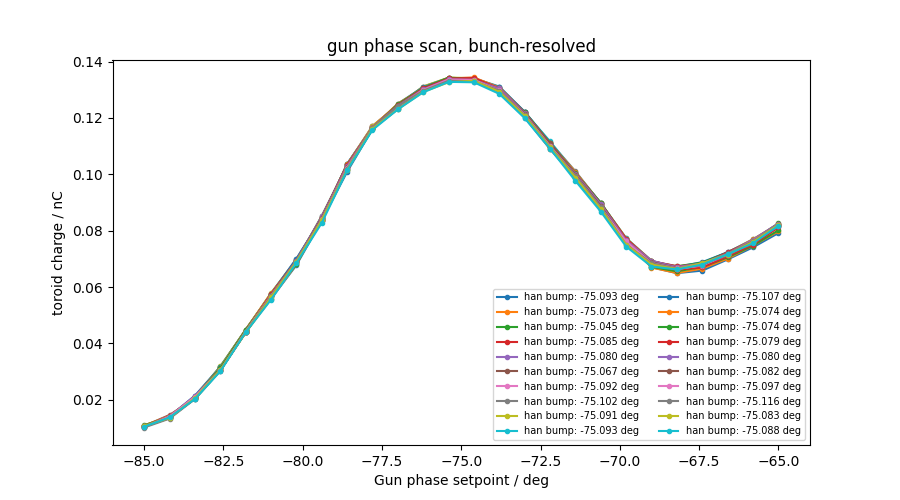

In [137]:

x = []
rows = []

for mp_id, entry in scan_data.items():
    dm = mask_data(entry, condition="GnD (Gun dump/DUMP)", facility='FLASH', tol=0.01)
    x.append(entry['setpoint'])
    rows.append(dict(zip(dm['toroid_charge']['bunch_idx'], dm['toroid_charge']['y'])))

order = np.argsort(x)
x = np.array(x)[order]
rows = [rows[i] for i in order]

all_bunches = sorted(set().union(*[r.keys() for r in rows]))

plt.figure(figsize=(9, 5))
for b in all_bunches:
    y = np.array([r.get(b, np.nan) for r in rows])

    popt=np.polyfit(x[x<-70],np.log(y[x<-70]),3)
    yfit=np.polyval(popt,xfit)
    yfit=np.exp(yfit)

    extremum=thirdOrdExtremum(popt)
    plt.plot(x, y, marker='.', label=f'han bump: {extremum[1]:.3f} deg')

plt.xlabel('Gun phase setpoint / deg')
plt.ylabel('toroid charge / nC')
plt.title('gun phase scan, bunch-resolved')
plt.legend(ncol=2, fontsize=7)
plt.show()

#### other tests

In [7]:
scan_data=run_scan([-1,-1,0,0,1,1],'FLASH.RF/LLRF.CONTROLLER/CTRL.GUN/SP.PHASE' , channels, wait=0.5)

In [15]:
dataCharge=[doocs4py.get('FLASH.DIAG/TOROID/3GUN/CHARGE.TD') for i in range(10) ]

In [16]:
dataRF=[doocs4py.get('FLASH.RF/LLRF.CONTROLLER/VS.GUN/PHASE.TD') for i in range(10) ]

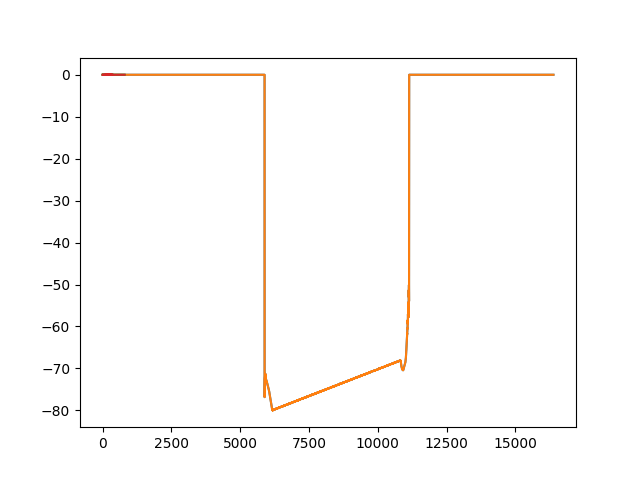

In [33]:
plt.plot(dataCharge[0].get_data().get_data())
plt.show()

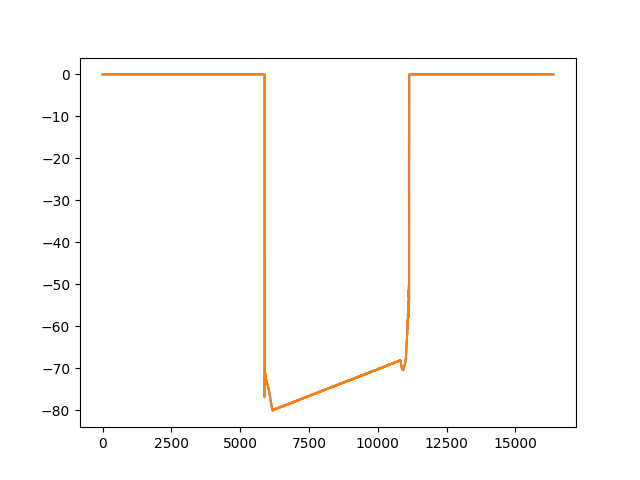

In [30]:
plt.plot((dataRF[0].get_data().get_data()))
plt.show()

In [31]:
setpoints = []
per_sp_bunch = []
per_sp_y = []

for mp_id, d in scan_data.items():
    sp = d['setpoint']
    dm = mask_data(d, condition=2)
    setpoints.append(sp)
    per_sp_bunch.append(dm['toroid_charge']['bunch_idx'])
    per_sp_y.append(dm['toroid_charge']['y'])

setpoints = np.array(setpoints)
order = np.argsort(setpoints)
setpoints    = setpoints[order]
per_sp_bunch = [per_sp_bunch[i] for i in order]
per_sp_y     = [per_sp_y[i] for i in order]

all_bunches   = np.unique(np.concatenate(per_sp_bunch))
bunch_to_col  = {b: i for i, b in enumerate(all_bunches)}

bunch_matrix = np.full((len(setpoints), len(all_bunches)), np.nan)
for row, (bidx, y) in enumerate(zip(per_sp_bunch, per_sp_y)):
    cols = [bunch_to_col[b] for b in bidx]
    bunch_matrix[row, cols] = y 

print('shape:', bunch_matrix.shape, '| NaN:', np.isnan(bunch_matrix).sum(), '/', bunch_matrix.size)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.pcolormesh(all_bunches, setpoints, bunch_matrix, shading='nearest', cmap='RdBu_r')
ax.set_xlabel('Bunch index (aus Pattern)')
ax.set_ylabel('Gun phase setpoint (deg)')
fig.colorbar(im, ax=ax, label='toroid_charge 3GUN (nC)')
fig.tight_layout()
plt.show()

KeyError: 't'

shape: (6, 574) | NaN: 0 / 3444


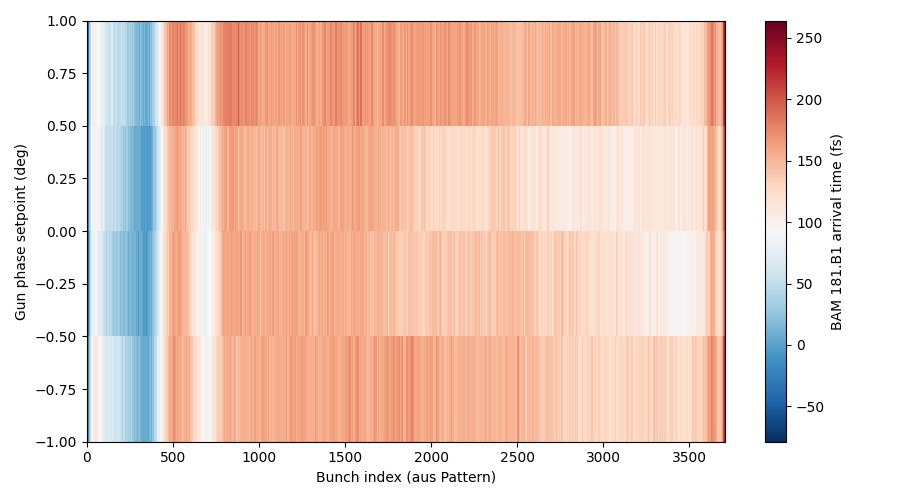

In [6]:
setpoints = []
per_sp_bunch = []
per_sp_y = []

for mp_id, d in scan_data.items():
    sp = d['setpoint']
    dm = mask_data(d, condition=4)
    setpoints.append(sp)
    per_sp_bunch.append(dm['bam_181_b1']['bunch_idx'])
    per_sp_y.append(dm['bam_181_b1']['y'])

setpoints = np.array(setpoints)
order = np.argsort(setpoints)
setpoints    = setpoints[order]
per_sp_bunch = [per_sp_bunch[i] for i in order]
per_sp_y     = [per_sp_y[i] for i in order]

all_bunches   = np.unique(np.concatenate(per_sp_bunch))
bunch_to_col  = {b: i for i, b in enumerate(all_bunches)}

bunch_matrix = np.full((len(setpoints), len(all_bunches)), np.nan)
for row, (bidx, y) in enumerate(zip(per_sp_bunch, per_sp_y)):
    cols = [bunch_to_col[b] for b in bidx]
    bunch_matrix[row, cols] = y 

print('shape:', bunch_matrix.shape, '| NaN:', np.isnan(bunch_matrix).sum(), '/', bunch_matrix.size)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.pcolormesh(all_bunches, setpoints, bunch_matrix, shading='nearest', cmap='RdBu_r')
ax.set_xlabel('Bunch index (aus Pattern)')
ax.set_ylabel('Gun phase setpoint (deg)')
fig.colorbar(im, ax=ax, label='BAM 181.B1 arrival time (fs)')
fig.tight_layout()
plt.show()

In [7]:
scan_data = track_data_simple(n_shots=50, channels=channels, wait=0.1)

shape: (50, 574) | NaN: 0 / 28700


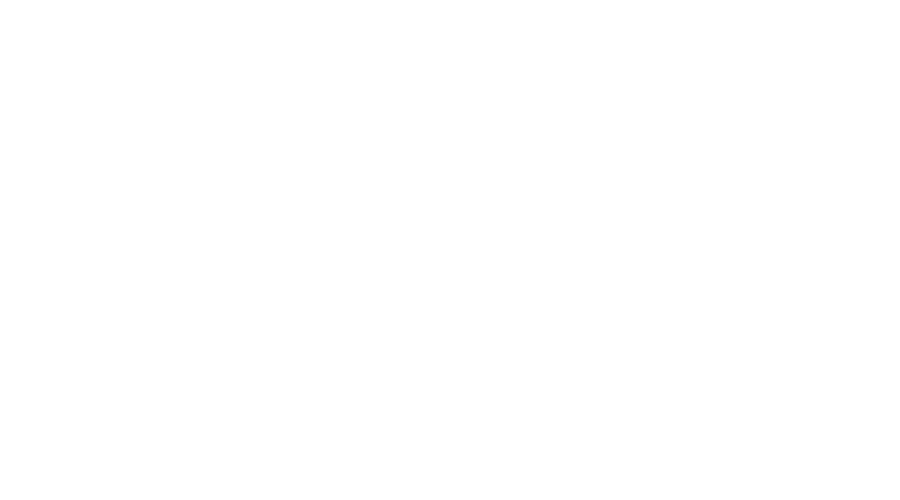

In [8]:
setpoints = []
per_sp_bunch = []
per_sp_y = []

for mp_id, d in scan_data.items():
    sp = np.mean(d['gun_phase']['y'])   # Ist-Wert als "x-Achse" statt Setpoint
    dm = mask_data(d, condition=4)
    setpoints.append(sp)
    per_sp_bunch.append(dm['bam_181_b1']['bunch_idx'])
    per_sp_y.append(dm['bam_181_b1']['y'])

setpoints = np.array(setpoints)
order = np.argsort(setpoints)
setpoints    = setpoints[order]
per_sp_bunch = [per_sp_bunch[i] for i in order]
per_sp_y     = [per_sp_y[i] for i in order]

all_bunches   = np.unique(np.concatenate(per_sp_bunch))
bunch_to_col  = {b: i for i, b in enumerate(all_bunches)}

bunch_matrix = np.full((len(setpoints), len(all_bunches)), np.nan)
for row, (bidx, y) in enumerate(zip(per_sp_bunch, per_sp_y)):
    cols = [bunch_to_col[b] for b in bidx]
    bunch_matrix[row, cols] = y

print('shape:', bunch_matrix.shape, '| NaN:', np.isnan(bunch_matrix).sum(), '/', bunch_matrix.size)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.pcolormesh(all_bunches, setpoints, bunch_matrix, shading='nearest', cmap='RdBu_r')
ax.set_xlabel('Bunch index (aus Pattern)')
ax.set_ylabel('Gun phase setpoint (deg)')
fig.colorbar(im, ax=ax, label='BAM 181.B1 arrival time (fs)')
fig.tight_layout()
plt.show()

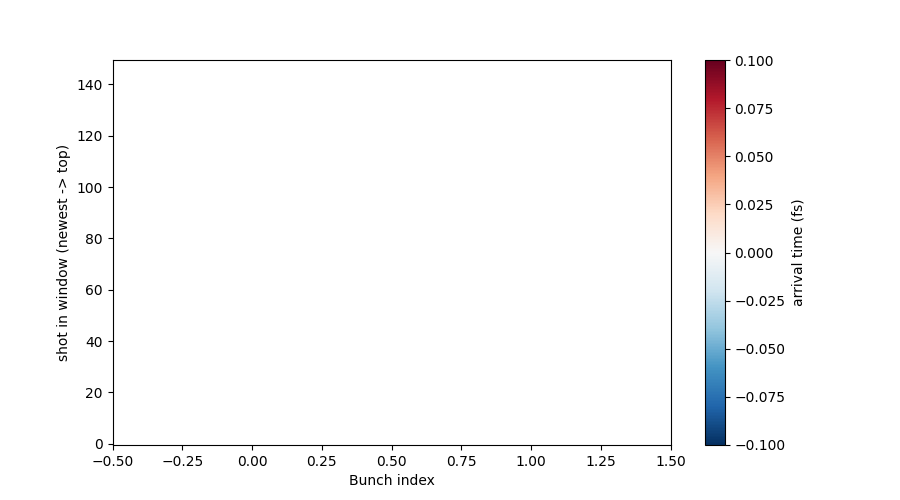

Gestoppt bei shot 17


In [14]:
scan_data,x, b,y,c = await track_data(channels, window=150, wait=0.1, live=True,condition=2)

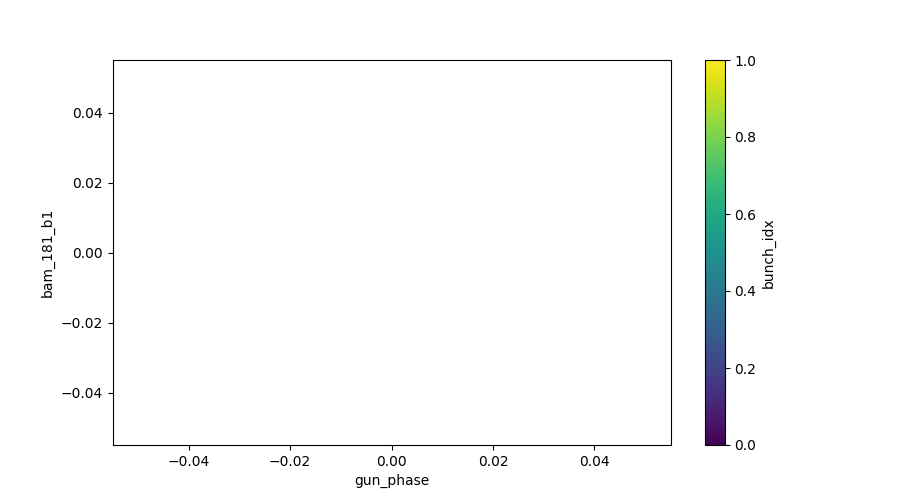

Gestoppt bei shot 18


In [13]:
scan_data,x, b,y,c = await track_data(channels, window=150, wait=0.1, live=True,condition=2,plot_mode='scatter', y_key='bam_181_b1', x_key='gun_phase')

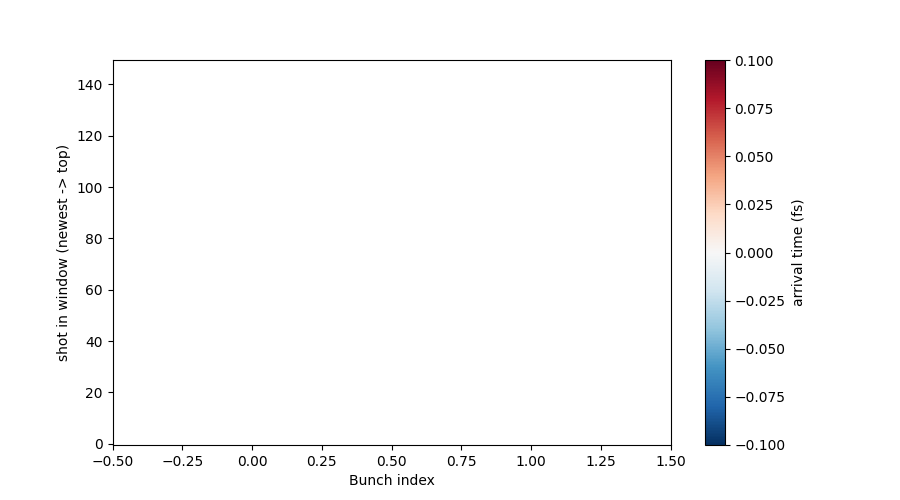

Gestoppt bei shot 12


In [12]:
scan_data,x, b,y,c = await track_data(channels, n_shots=150,window=150, wait=0.1, live=True,condition=2)

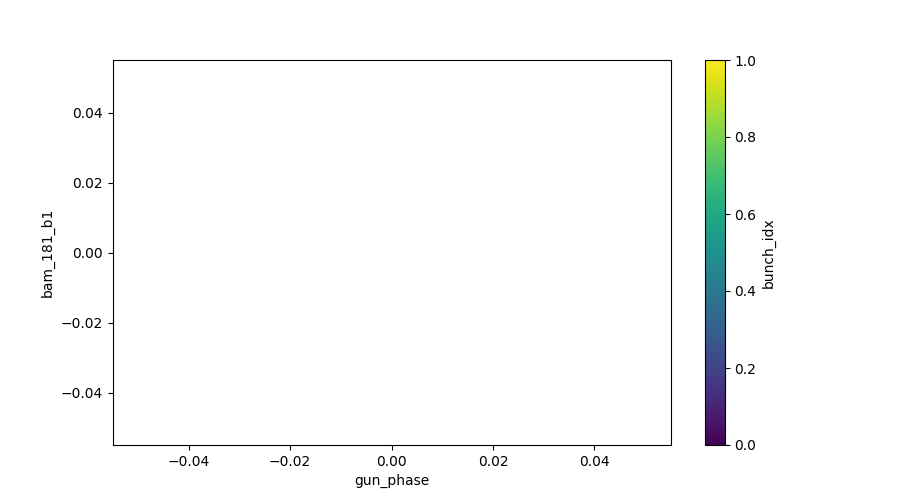

In [7]:
scan_data,x, b,y = await track_data(channels,n_shots=150, window=150, wait=0.1, live=True,condition=2,plot_mode='scatter', y_key='bam_181_b1', x_key='gun_phase')

In [20]:
scan_data, x, b, y, c = await track_data(
    channels, window=150, wait=0.1, live=True, condition=2,
    plot_mode='scatter3d', x_key='gun_phase', y_key='bam_181_b1', c_key='toroid_charge'
)

353

In [16]:
scan_data,x, b,y,c = await track_data(channels, n_shots=150, live=False,wait=0.1,condition=2)

In [17]:
def to_long_df(scan_data, y_key, x_key, condition=4, facility='XFEL'):
    """scan_data -> DataFrame mit Spalten mp_id, bunch_idx, x, y.
       x_key und y_key sind beide TD-Kanaele; werden pro Shot ueber
       bunch_idx gematcht (Zeitbasis/Offset kann zwischen Kanaelen leicht abweichen)."""
    rows = []
    for mp_id, entry in scan_data.items():
        dm = mask_data(entry, condition=condition, facility=facility, keys=[x_key, y_key])
        bx, by = dm[x_key]['bunch_idx'], dm[y_key]['bunch_idx']
        common, ix, iy = np.intersect1d(bx, by, return_indices=True)
        for b, xv, yv in zip(common, dm[x_key]['y'][ix], dm[y_key]['y'][iy]):
            rows.append({'mp_id': mp_id, 'bunch_idx': int(b), 'x': xv, 'y': yv})
    return pd.DataFrame(rows)

In [18]:
df=to_long_df(scan_data, y_key='bam_181_b1', x_key='gun_phase',
               condition=4, facility='XFEL')

Text(0, 0.5, 'y')

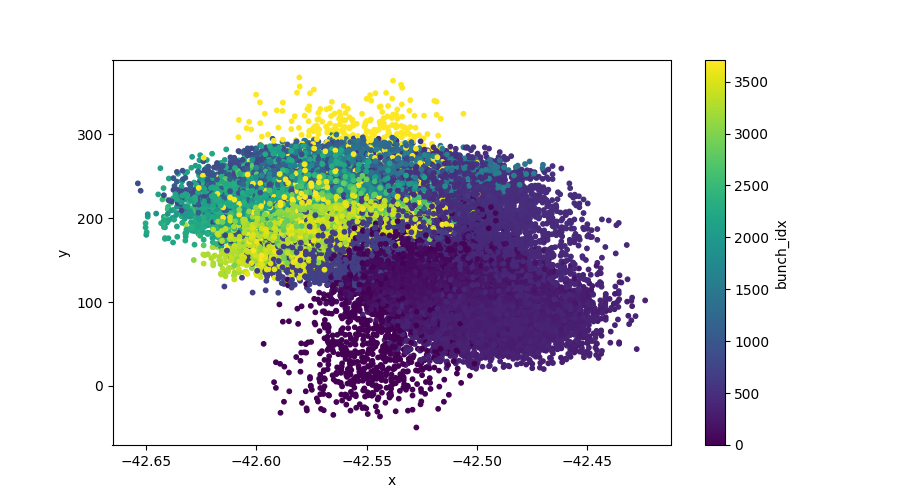

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(df['x'], df['y'], c=df['bunch_idx'], cmap='viridis', s=10)
fig.colorbar(sc, ax=ax, label='bunch_idx')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.close(fig)   # genau diese Figure schliessen, nicht "die letzte"

In [42]:
plt.close('all')

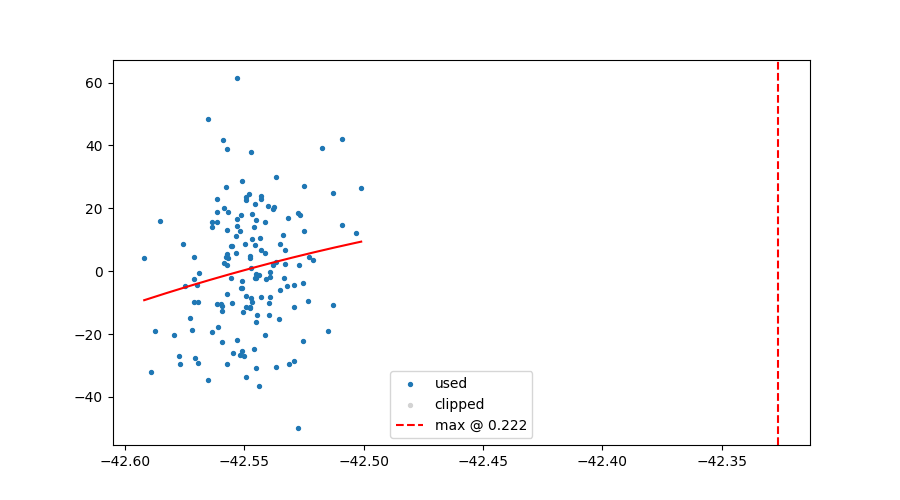

In [62]:
fig, ax = plt.subplots(figsize=(9, 5))

for i,(b, g) in enumerate(df.groupby('bunch_idx')):
    if  i ==0:
        xm=np.mean(g['x'].values)
        x0, coef, mask = robust_parabola_max(g['x'].values-xm, g['y'].values)
        xx = np.linspace(g['x'].min(), g['x'].max(), 200)-xm
        
        ax.scatter(g['x'][mask], g['y'][mask], s=8, label='used')
        ax.scatter(g['x'][~mask], g['y'][~mask], s=8, c='lightgray', label='clipped')
        ax.plot(xx+xm, np.polyval(coef, xx), 'r-')
        ax.axvline(x0+xm, color='r', ls='--', label=f'max @ {x0:.3f}')
        ax.legend()
#plt.close(fig) 

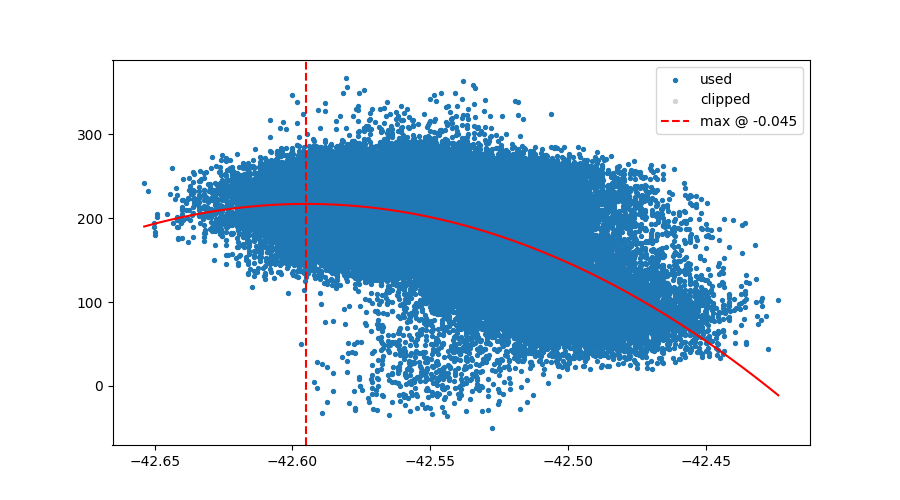

In [59]:
xm=np.mean(df['x'].values)
x0, coef, mask = robust_parabola_max(df['x'].values-xm, df['y'].values)
xx = np.linspace(df['x'].min(), df['x'].max(), 200)-xm
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df['x'][mask], df['y'][mask], s=8, label='used')
ax.scatter(df['x'][~mask], df['y'][~mask], s=8, c='lightgray', label='clipped')
ax.plot(xx+xm, np.polyval(coef, xx), 'r-')
ax.axvline(x0+xm, color='r', ls='--', label=f'max @ {x0:.3f}')
ax.legend()

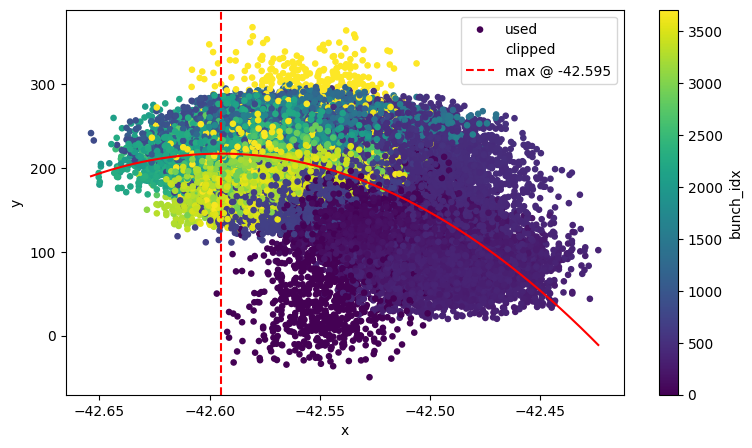

In [63]:
xm = np.mean(df['x'].values)
x0, coef, mask = robust_parabola_max(df['x'].values - xm, df['y'].values)
xx = np.linspace(df['x'].min(), df['x'].max(), 200) - xm

fig, ax = plt.subplots(figsize=(9, 5))

sc = ax.scatter(df['x'][mask], df['y'][mask], c=df['bunch_idx'][mask],
                 cmap='viridis', s=14, marker='o', label='used')
ax.scatter(df['x'][~mask], df['y'][~mask], c=df['bunch_idx'][~mask],
           cmap='viridis', s=14, marker='x', label='clipped')

fig.colorbar(sc, ax=ax, label='bunch_idx')
ax.plot(xx + xm, np.polyval(coef, xx), 'r-', lw=1.5)
ax.axvline(x0 + xm, color='r', ls='--', label=f'max @ {x0+xm:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.legend()
plt.close(fig)
fig

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
for b, g in df.groupby('bunch_idx'):
    ax.scatter(g['x'], g['y'], s=8, label=f'bunch {b}')
    if len(g) >= 5:
        x0, coef, mask = robust_parabola_max(g['x'].values, g['y'].values)
        ax.axvline(x0, ls='--', alpha=0.4)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(fontsize=7, ncol=2)

In [31]:
from scipy.signal import find_peaks

def find_envelope_peak(phase, y, bin_deg=0.2, min_width_deg=3.0):
    order = np.argsort(phase)
    phase, y = phase[order], y[order]
    bins = np.arange(phase.min(), phase.max() + bin_deg, bin_deg)
    idx = np.digitize(phase, bins)
    uniq = np.unique(idx)
    xb = np.array([phase[idx == i].mean() for i in uniq])
    yb = np.array([np.median(y[idx == i]) for i in uniq])  # Median robust ggü. Multipacting-Spikes im Bin

    peaks, props = find_peaks(yb, width=min_width_deg / bin_deg, prominence=0.05 * yb.ptp())
    if len(peaks) == 0:
        return None
    best = peaks[np.argmax(props['widths'])]   # breitester Peak = Envelope, nicht Multipacting
    return xb[best], yb[best], (xb, yb, peaks, props)

In [58]:
def robust_parabola_max(phase, y, n_iter=4, sigma=12.0):
    mask = np.ones(len(phase), dtype=bool)
    coef = None
    for _ in range(n_iter):
        coef = np.polyfit(phase[mask], y[mask], 2)
        resid = y - np.polyval(coef, phase)
        s = np.std(resid[mask])
        mask = np.abs(resid) < sigma * s
    x0 = -coef[1] / (2 * coef[0])
    return x0, coef, mask